# 04 · Exploratory data analysis

## Purpose

Describe target balance and observed numeric and categorical feature distributions before modeling.

## Method

Use the actual active CSV, show target proportions, numeric summaries, and available grouped distributions. Treat observed associations as descriptive.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

A single file without transaction dates cannot show temporal drift. Category groups with few observations should be interpreted cautiously.

## References

See the competition field notes in returnwise.data.profile.KNOWN_DESCRIPTIONS.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '04 · Exploratory data analysis')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 04 · Exploratory data analysis


,feature,count,mean,std,min,25%,50%,75%,max
0,customer_age,200000.0,56.479545,17.952930,10.000000,44.000000,58.000000,72.000000,87.000000
1,product_price,200000.0,37.984234,45.626883,-183.292092,6.876686,24.461142,53.355820,855.078645
2,discount_percent,200000.0,42.872056,21.510490,-7.540832,25.848785,42.945197,62.642248,78.791547
3,product_rating,200000.0,2.812805,1.219874,0.445342,1.789263,2.818731,3.810169,5.452690
4,past_purchase_count,200000.0,9.620210,3.139979,1.000000,8.000000,9.000000,10.000000,26.000000
5,past_return_rate,200000.0,0.215114,0.137162,-0.060878,0.118326,0.191392,0.282027,0.866420
6,delivery_delay_days,200000.0,0.625050,2.331221,-9.049981,-0.751862,0.519040,1.896547,7.961333
7,session_length_minutes,200000.0,77.406138,36.394216,-11.010479,48.995295,81.562252,108.209400,137.652911
8,num_product_views,200000.0,14.654450,12.659400,-5.000000,3.000000,13.000000,25.000000,44.000000
9,used_coupon,200000.0,0.615400,0.486502,0.000000,0.000000,1.000000,1.000000,1.000000


,feature,count,unique,top,freq
0,device_type,200000,3,mobile,109371
1,product_category,200000,6,toys,48287
2,shipping_method,200000,3,standard,131311
3,payment_method,200000,4,debit_card,56667


,returned,rows,share
0,0,105081,0.525405
1,1,94919,0.474595


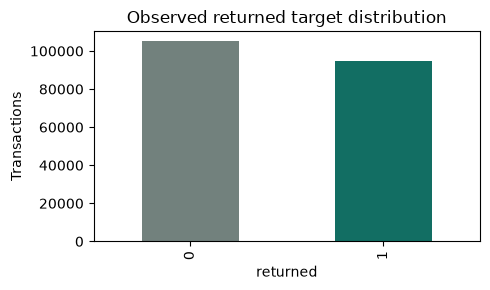

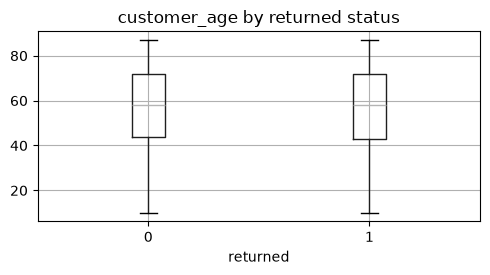

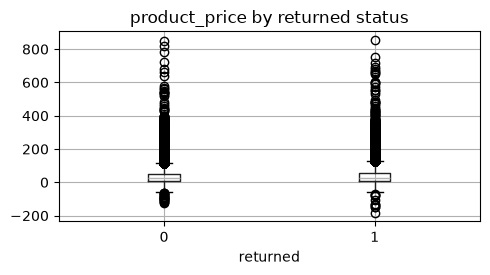

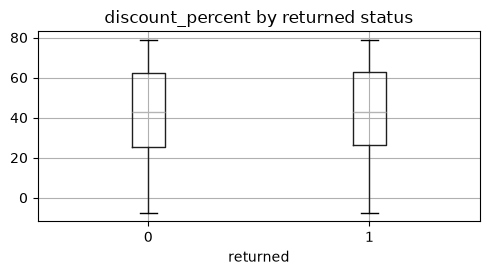

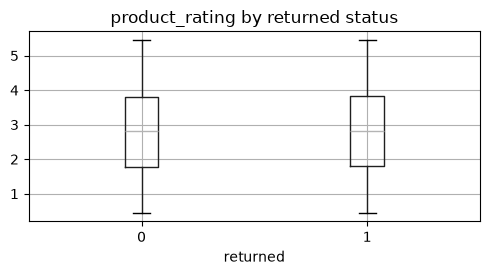

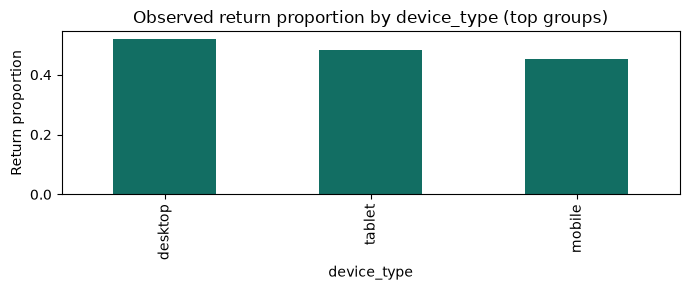

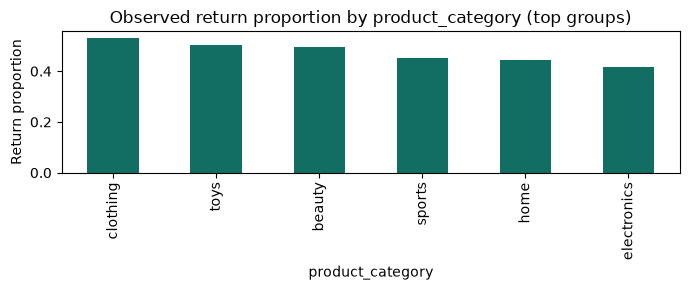

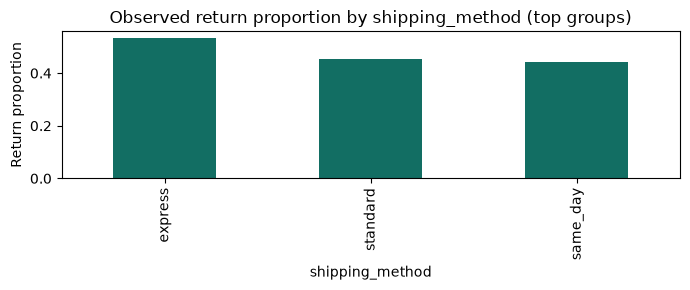

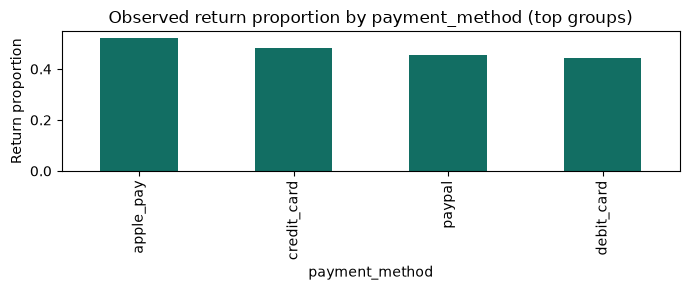

In [2]:
from returnwise.data.profile import eda_summaries
from returnwise.storage import load_active_dataset
import matplotlib.pyplot as plt
import pandas as pd

frame, manifest = load_active_dataset()
if frame is None:
    raise RuntimeError('No active dataset. Complete notebook 01 first.')
eda = eda_summaries(frame)
display(eda['numeric_summary'])
display(eda['categorical_summary'])
if eda['target_distribution'] is not None:
    display(eda['target_distribution'])
    ax = frame['returned'].value_counts(dropna=False).sort_index().plot.bar(figsize=(5, 3), color=['#72817D', '#126E63'], title='Observed returned target distribution')
    ax.set_xlabel('returned')
    ax.set_ylabel('Transactions')
    plt.tight_layout()
    plt.show()
    numeric = frame.select_dtypes(include='number').columns.drop('returned', errors='ignore')
    for feature in list(numeric[:4]):
        ax = frame.boxplot(column=feature, by='returned', figsize=(5, 3))
        ax.set_title(f'{feature} by returned status')
        plt.suptitle('')
        plt.tight_layout()
        plt.show()
    categorical = [c for c in frame.columns if c != 'returned' and not pd.api.types.is_numeric_dtype(frame[c])]
    for feature in categorical[:4]:
        grouped = frame.groupby(feature, dropna=False)['returned'].mean().sort_values(ascending=False).head(12)
        ax = grouped.plot.bar(figsize=(7, 3), color='#126E63', title=f'Observed return proportion by {feature} (top groups)')
        ax.set_ylabel('Return proportion')
        plt.tight_layout()
        plt.show()
else:
    print('No return target is present; supervised EDA is not available.')
